# NYC Taxi Trip Duration: Prediction and Performance Analysis

**Course:** Applied Data Science Skill Lab, CSE (Data Science), RVCE
**Mini-Project and Experiment 3.4:** Prediction and Performance Analysis using a Trained Machine Learning Model
**Team members:** _add names and USNs_

This notebook follows the six-stage mini-project workflow:

**Problem Identification → Data Acquisition → Data Preparation → Exploratory Data Analysis → Visualization & Predictive Modelling → Interpretation & Presentation**

The eight tasks of Experiment 3.4 are covered inside Stage 5B and are tagged **[Exp 3.4 – Task n]**.

## Stage 1: Problem Identification

**Problem statement.** Taxi trip time in a large city depends on distance, time of day, day of week and location. Passengers, drivers and fleet operators cannot predict it reliably from distance alone because traffic and demand change through the day. This project analyses New York City yellow-taxi trips from January to June 2016 and builds a model that predicts **how long a trip will take (in seconds)** from information known at pickup time.

**Objectives**
1. Acquire and document the NYC Taxi Trip Duration dataset.
2. Clean and prepare the data, documenting every decision.
3. Explore how trip duration varies with distance, hour, weekday, month, vendor and passenger count.
4. Build and compare regression models using Scikit-learn.
5. Evaluate the models on unseen test data with MAE, RMSE and R², and interpret their usefulness and limitations.

**Analytical questions**
- Q1. How is trip duration distributed, and are the extreme values errors or real?
- Q2. How strongly does trip distance explain duration?
- Q3. How do demand and trip duration change across hours of the day, weekdays and months?
- Q4. Do vendor, passenger count or the store-and-forward flag matter?
- Q5. How accurately can duration be predicted from pickup-time information, and where does the model fail?

**Expected outcomes.** A cleaned dataset, a set of labelled visualizations with interpretation, and a regression model that clearly beats a naive baseline.

**Intended application.** Estimated-time-of-arrival (ETA) and fare estimation, driver dispatch planning, and urban mobility analysis.

## Stage 2: Data Acquisition

**Dataset:** NYC Taxi Trip Duration
**Source:** Kaggle competition *nyc-taxi-trip-duration* (https://www.kaggle.com/competitions/nyc-taxi-trip-duration/data). The trip records originate from the NYC Taxi & Limousine Commission (TLC) yellow-taxi data for 2016.
**Usage:** The data is used for academic purposes under the Kaggle competition rules. It contains no passenger names or other direct personal identifiers, and trip IDs are anonymous.

**Sample used here:** the full `train.csv` has about 1.46 million trips. Because of file-size limits, a **100,000-trip sample** of `train.csv` is used for the whole project (stored as `data/train_sample.csv`). The notebook also runs unchanged on the full file.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 11})
ACCENT = "#2b6cb0"
RANDOM_STATE = 42
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

# The notebook looks for the data in the usual places (repo, Colab, current folder).
CANDIDATES = [Path("../data/train_sample.csv"), Path("data/train_sample.csv"), Path("train_sample.csv"),
              Path("train.csv"), Path("/content/train.csv")]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
assert DATA_PATH is not None, "Put train_sample.csv (or train.csv) in the data/ folder."

REPO_MODE = Path("../data").exists()
FIG_DIR = Path("../figures") if REPO_MODE else Path("figures")
DATA_DIR = Path("../data") if REPO_MODE else Path(".")
OUT_DIR = Path("../outputs") if REPO_MODE else Path("outputs")
for d in (FIG_DIR, OUT_DIR):
    d.mkdir(exist_ok=True)
print("Data file:", DATA_PATH)

Data file: ../data/train_sample.csv


In [2]:
# Optional (Google Colab only): download the full dataset straight from Kaggle.
# 1) Upload your kaggle.json API token, 2) accept the competition rules on Kaggle, 3) uncomment:
# !pip install -q kaggle
# !kaggle competitions download -c nyc-taxi-trip-duration && unzip -o nyc-taxi-trip-duration.zip train.zip && unzip -o train.zip
print("Skipped: using the local sample.")

Skipped: using the local sample.


In [3]:
raw = pd.read_csv(DATA_PATH)
print(f"Records: {raw.shape[0]:,}   Attributes: {raw.shape[1]}")
display(raw.head())

Records: 100,000   Attributes: 11
          id  vendor_id      pickup_datetime     dropoff_datetime  passenger_count  pickup_longitude  pickup_latitude  dropoff_longitude  dropoff_latitude store_and_fwd_flag  trip_duration
0  id2875421          2  2016-03-14 17:24:55  2016-03-14 17:32:30                1        -73.982155        40.767937         -73.964630         40.765602                  N            455
1  id2377394          1  2016-06-12 00:43:35  2016-06-12 00:54:38                1        -73.980415        40.738564         -73.999481         40.731152                  N            663
2  id3858529          2  2016-01-19 11:35:24  2016-01-19 12:10:48                1        -73.979027        40.763939         -74.005333         40.710087                  N           2124
3  id3504673          2  2016-04-06 19:32:31  2016-04-06 19:39:40                1        -74.010040        40.719971         -74.012268         40.706718                  N            429
4  id2181028         

In [4]:
dictionary = pd.DataFrame({
    "Variable": ["id", "vendor_id", "pickup_datetime", "dropoff_datetime", "passenger_count",
                 "pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude",
                 "store_and_fwd_flag", "trip_duration"],
    "Type": ["identifier", "categorical (1/2)", "datetime", "datetime", "numerical (discrete)",
             "numerical", "numerical", "numerical", "numerical", "categorical (Y/N)", "numerical (target)"],
    "Description": ["Unique trip identifier",
                    "Taxi technology provider that supplied the record",
                    "Date and time the meter was engaged",
                    "Date and time the meter was disengaged (not available when predicting)",
                    "Number of passengers in the vehicle (driver-entered)",
                    "Longitude where the meter was engaged", "Latitude where the meter was engaged",
                    "Longitude where the meter was disengaged", "Latitude where the meter was disengaged",
                    "Y = trip record was held in vehicle memory before being sent to the vendor (no connection)",
                    "Trip duration in seconds (dropoff minus pickup)"]})
display(dictionary)

pick = pd.to_datetime(raw["pickup_datetime"])
print("\nTime period of pickups:", pick.min(), "to", pick.max())
print("\nData types:")
print(raw.dtypes.to_string())

              Variable                  Type                                                                                 Description
0                   id            identifier                                                                      Unique trip identifier
1            vendor_id     categorical (1/2)                                           Taxi technology provider that supplied the record
2      pickup_datetime              datetime                                                         Date and time the meter was engaged
3     dropoff_datetime              datetime                      Date and time the meter was disengaged (not available when predicting)
4      passenger_count  numerical (discrete)                                        Number of passengers in the vehicle (driver-entered)
5     pickup_longitude             numerical                                                       Longitude where the meter was engaged
6      pickup_latitude             numeri

**Limitations and constraints of the dataset**
- Covers only **six months (Jan to Jun 2016)** of one taxi type; patterns for other seasons, years or ride-hailing services are not represented.
- No weather, traffic, road-network or event information, which strongly affect trip time.
- `passenger_count` is entered by the driver and can be wrong (it contains 0).
- GPS coordinates are only start and end points, not the route taken.
- `dropoff_datetime` is simply pickup + duration, so it must **not** be used as a model input (target leakage).

## Stage 3: Data Preparation

### 3.1 Inspect structure and data types

In [5]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 11 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   id                  100000 non-null  str    
 1   vendor_id           100000 non-null  int64  
 2   pickup_datetime     100000 non-null  str    
 3   dropoff_datetime    100000 non-null  str    
 4   passenger_count     100000 non-null  int64  
 5   pickup_longitude    100000 non-null  float64
 6   pickup_latitude     100000 non-null  float64
 7   dropoff_longitude   100000 non-null  float64
 8   dropoff_latitude    100000 non-null  float64
 9   store_and_fwd_flag  100000 non-null  str    
 10  trip_duration       100000 non-null  int64  
dtypes: float64(4), int64(3), str(4)
memory usage: 8.4 MB


### 3.2 Missing values, duplicates and consistency checks

In [6]:
print("Missing values per column:")
print(raw.isna().sum().to_string())
print("\nFully duplicated rows :", raw.duplicated().sum())
print("Duplicated trip ids   :", raw["id"].duplicated().sum())

pickup = pd.to_datetime(raw["pickup_datetime"])
dropoff = pd.to_datetime(raw["dropoff_datetime"])
print("\nDropoff before/at pickup          :", (dropoff <= pickup).sum())
print("Duration != dropoff - pickup (sec):", ((dropoff - pickup).dt.total_seconds() != raw["trip_duration"]).sum())
print("\nvendor_id values        :", raw["vendor_id"].unique().tolist())
print("store_and_fwd_flag      :", sorted(raw["store_and_fwd_flag"].unique()))
print("passenger_count values  :", sorted(raw["passenger_count"].unique().tolist()))

Missing values per column:
id                    0
vendor_id             0
pickup_datetime       0
dropoff_datetime      0
passenger_count       0
pickup_longitude      0
pickup_latitude       0
dropoff_longitude     0
dropoff_latitude      0
store_and_fwd_flag    0
trip_duration         0

Fully duplicated rows : 0
Duplicated trip ids   : 0

Dropoff before/at pickup          : 0
Duration != dropoff - pickup (sec): 0

vendor_id values        : [2, 1]
store_and_fwd_flag      : ['N', 'Y']
passenger_count values  : [0, 1, 2, 3, 4, 5, 6]


**Decision:** there are no missing values and no duplicates, and the recorded duration matches the timestamps exactly, so no imputation or de-duplication is needed. The remaining quality risk is *implausible values* (zero passengers, GPS points outside NYC, extreme or impossible durations), checked next.

### 3.3 Fix data formats and create derived variables
Derived variables (feature engineering):
- **Time features:** pickup hour, weekday, month, weekend flag, weekday rush-hour flag (07:00–10:00 and 16:00–19:00).
- **Distance features:** straight-line (haversine) distance, Manhattan-style distance (north-south plus east-west legs), and compass bearing, since taxis travel on a street grid.
- **log trip duration:** the raw duration is heavily right-skewed, so the model is trained on `log1p(duration)`.

In [7]:
def haversine(lat1, lon1, lat2, lon2):
    """Great-circle distance in km."""
    r = 6371.0088
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))


def bearing(lat1, lon1, lat2, lon2):
    """Initial compass bearing (degrees, 0-360)."""
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlon = lon2 - lon1
    x = np.sin(dlon) * np.cos(lat2)
    y = np.cos(lat1) * np.sin(lat2) - np.sin(lat1) * np.cos(lat2) * np.cos(dlon)
    return (np.degrees(np.arctan2(x, y)) + 360) % 360


def add_features(d):
    """Add derived variables. Works on training data and on new trips (used again in Stage 5B)."""
    d = d.copy()
    d["pickup_datetime"] = pd.to_datetime(d["pickup_datetime"])
    d["pickup_hour"] = d["pickup_datetime"].dt.hour
    d["pickup_weekday"] = d["pickup_datetime"].dt.weekday          # Monday = 0
    d["pickup_month"] = d["pickup_datetime"].dt.month
    d["pickup_date"] = d["pickup_datetime"].dt.date
    d["is_weekend"] = (d["pickup_weekday"] >= 5).astype(int)
    d["is_rush_hour"] = ((d["is_weekend"] == 0) &
                         (d["pickup_hour"].between(7, 9) | d["pickup_hour"].between(16, 18))).astype(int)
    d["store_fwd"] = (d["store_and_fwd_flag"] == "Y").astype(int)
    d["haversine_km"] = haversine(d["pickup_latitude"], d["pickup_longitude"],
                                  d["dropoff_latitude"], d["dropoff_longitude"])
    d["manhattan_km"] = (haversine(d["pickup_latitude"], d["pickup_longitude"], d["pickup_latitude"], d["dropoff_longitude"])
                         + haversine(d["pickup_latitude"], d["dropoff_longitude"], d["dropoff_latitude"], d["dropoff_longitude"]))
    d["bearing"] = bearing(d["pickup_latitude"], d["pickup_longitude"], d["dropoff_latitude"], d["dropoff_longitude"])
    d["log_haversine"] = np.log1p(d["haversine_km"])
    return d


df = add_features(raw)
df["dropoff_datetime"] = pd.to_datetime(df["dropoff_datetime"])
weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
df["weekday_name"] = pd.Categorical(df["pickup_weekday"].map(dict(enumerate(weekday_names))),
                                    categories=weekday_names, ordered=True)
# These two use the target, so they are for analysis only and are never model inputs:
df["log_duration"] = np.log1p(df["trip_duration"])
df["speed_kmh"] = df["haversine_km"] / (df["trip_duration"] / 3600)
display(df[["pickup_datetime", "pickup_hour", "weekday_name", "is_rush_hour", "haversine_km",
            "manhattan_km", "bearing", "trip_duration", "speed_kmh"]].head())

      pickup_datetime  pickup_hour weekday_name  is_rush_hour  haversine_km  manhattan_km     bearing  trip_duration  speed_kmh
0 2016-03-14 17:24:55           17          Mon             1      1.498523      1.735436   99.970196            455  11.856445
1 2016-06-12 00:43:35            0          Sun             0      1.805510      2.430509  242.846232            663   9.803672
2 2016-01-19 11:35:24           11          Tue             0      6.385107      8.203586  200.319835           2124  10.822216
3 2016-04-06 19:32:31           19          Wed             0      1.485500      1.661334  187.262300            429  12.465738
4 2016-03-26 13:30:55           13          Sat             0      1.188590      1.199458  179.473585            435   9.836608


### 3.4 Identify and handle implausible records
Rules below are applied only to records that are very likely **recording errors**, and the number removed by each rule is reported. Unusually long (but plausible) trips are *not* removed here; they are investigated in Stage 4 with the IQR method.

In [8]:
# Approximate bounding box around New York City
in_box = lambda lon, lat: lon.between(-74.30, -73.60) & lat.between(40.45, 41.00)
outside_nyc = ~(in_box(df["pickup_longitude"], df["pickup_latitude"]) &
                in_box(df["dropoff_longitude"], df["dropoff_latitude"]))

rules = {
    "0 passengers": df["passenger_count"].eq(0),
    "pickup/dropoff outside NYC bounding box": outside_nyc,
    "duration < 60 s (cancelled / meter error)": df["trip_duration"] < 60,
    "duration > 3 h (meter left running)": df["trip_duration"] > 3 * 3600,
    "implied speed > 120 km/h (impossible in city)": df["speed_kmh"] > 120,
}
summary = pd.DataFrame({"records_flagged": {k: int(v.sum()) for k, v in rules.items()}})
summary["percent_of_data"] = (summary["records_flagged"] / len(df) * 100).round(3)
display(summary)

invalid = np.logical_or.reduce(list(rules.values()))
print(f"\nUnique records removed: {invalid.sum():,} of {len(df):,} ({invalid.mean():.2%})")
clean = df.loc[~invalid].reset_index(drop=True)
print(f"Cleaned dataset: {clean.shape[0]:,} records")

                                               records_flagged  percent_of_data
0 passengers                                                 1            0.001
pickup/dropoff outside NYC bounding box                     49            0.049
duration < 60 s (cancelled / meter error)                  592            0.592
duration > 3 h (meter left running)                        129            0.129
implied speed > 120 km/h (impossible in city)                6            0.006

Unique records removed: 761 of 100,000 (0.76%)
Cleaned dataset: 99,239 records


**Decisions and reasons**
- **0 passengers:** a trip with nobody in the car is not a valid passenger trip.
- **Outside NYC box:** coordinates far from the city (e.g. other states) are GPS errors or very atypical long-distance trips that this model is not designed for.
- **< 60 s and > 3 h:** such durations are not realistic urban taxi trips (cancelled fares, meter left running).
- **Speed > 120 km/h:** physically impossible in the city and indicates a bad coordinate or timestamp.
- Short, slow or round-trip journeys that pass these rules are **kept**.

### 3.5 Numerical vs categorical variables and feature selection

In [9]:
numerical = ["passenger_count", "pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude",
             "haversine_km", "manhattan_km", "bearing", "pickup_hour", "pickup_weekday", "pickup_month"]
categorical = ["vendor_id", "store_and_fwd_flag", "is_weekend", "is_rush_hour"]
print("Numerical  :", numerical)
print("Categorical:", categorical)

FEATURES = ["vendor_id", "passenger_count", "store_fwd",
            "pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude",
            "pickup_hour", "pickup_weekday", "pickup_month", "is_weekend", "is_rush_hour",
            "haversine_km", "log_haversine", "manhattan_km", "bearing"]
TARGET = "trip_duration"
excluded = {"id": "identifier, no predictive meaning",
            "dropoff_datetime": "equals pickup + duration, so it leaks the target",
            "speed_kmh / log_duration": "computed from the target, analysis only",
            "pickup_datetime / pickup_date": "replaced by hour, weekday, month features"}
print("\nModel input features (%d): %s" % (len(FEATURES), FEATURES))
print("Target:", TARGET)
print("\nExcluded variables:")
for k, v in excluded.items():
    print(f"  - {k}: {v}")

Numerical  : ['passenger_count', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'haversine_km', 'manhattan_km', 'bearing', 'pickup_hour', 'pickup_weekday', 'pickup_month']
Categorical: ['vendor_id', 'store_and_fwd_flag', 'is_weekend', 'is_rush_hour']

Model input features (16): ['vendor_id', 'passenger_count', 'store_fwd', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'pickup_hour', 'pickup_weekday', 'pickup_month', 'is_weekend', 'is_rush_hour', 'haversine_km', 'log_haversine', 'manhattan_km', 'bearing']
Target: trip_duration

Excluded variables:
  - id: identifier, no predictive meaning
  - dropoff_datetime: equals pickup + duration, so it leaks the target
  - speed_kmh / log_duration: computed from the target, analysis only
  - pickup_datetime / pickup_date: replaced by hour, weekday, month features


In [10]:
cleaned_path = DATA_DIR / "train_cleaned.csv"
clean.drop(columns=["pickup_date", "weekday_name"]).to_csv(cleaned_path, index=False)
print("Saved cleaned dataset ->", cleaned_path, f"({len(clean):,} rows, {clean.shape[1] - 2} columns)")

Saved cleaned dataset -> ../data/train_cleaned.csv (99,239 rows, 23 columns)


## Stage 4: Exploratory Data Analysis (EDA)

### 4.1 Descriptive statistics (mean, median, mode, standard deviation, min, max, quartiles)

In [11]:
stat_cols = ["trip_duration", "haversine_km", "manhattan_km", "speed_kmh", "passenger_count", "pickup_hour"]
desc = clean[stat_cols].describe(percentiles=[0.25, 0.5, 0.75]).T
desc["mode"] = clean[stat_cols].mode().iloc[0]
desc["skewness"] = clean[stat_cols].skew()
display(desc[["count", "mean", "50%", "mode", "std", "min", "25%", "75%", "max", "skewness"]].rename(columns={"50%": "median", "25%": "Q1 (25%)", "75%": "Q3 (75%)"}).round(3))

                   count     mean   median   mode      std   min  Q1 (25%)  Q3 (75%)       max  skewness
trip_duration    99239.0  840.189  665.000  374.0  653.488  60.0   400.000  1076.000  9714.000     2.269
haversine_km     99239.0    3.440    2.104    0.0    3.889   0.0     1.245     3.885    47.765     2.832
manhattan_km     99239.0    4.445    2.696    0.0    5.173   0.0     1.585     5.007    67.616     3.032
speed_kmh        99239.0   14.395   12.802    0.0    7.668   0.0     9.183    17.804    79.945     1.400
passenger_count  99239.0    1.669    1.000    1.0    1.318   1.0     1.000     2.000     6.000     2.114
pickup_hour      99239.0   13.638   14.000   19.0    6.374   0.0     9.000    19.000    23.000    -0.453


### 4.2 Frequency tables for categorical variables

In [12]:
for col in ["vendor_id", "passenger_count", "store_and_fwd_flag", "weekday_name", "pickup_month", "is_rush_hour"]:
    vc = clean[col].value_counts().sort_index()
    table = pd.DataFrame({"count": vc, "percent": (vc / len(clean) * 100).round(2)})
    print(f"--- {col} ---")
    print(table.to_string(), "\n")

--- vendor_id ---
           count  percent
vendor_id                
1          46267    46.62
2          52972    53.38 

--- passenger_count ---
                 count  percent
passenger_count                
1                70180    70.72
2                14375    14.49
3                 4020     4.05
4                 1946     1.96
5                 5444     5.49
6                 3274     3.30 

--- store_and_fwd_flag ---
                    count  percent
store_and_fwd_flag                
N                   98662    99.42
Y                     577     0.58 

--- weekday_name ---
              count  percent
weekday_name                
Mon           12788    12.89
Tue           13738    13.84
Wed           14407    14.52
Thu           14918    15.03
Fri           15105    15.22
Sat           14965    15.08
Sun           13318    13.42 

--- pickup_month ---
              count  percent
pickup_month                
1             15706    15.83
2             16140    16.26
3   

### 4.3 Distribution of numerical variables

In [13]:
dist = pd.DataFrame({"skewness": clean[["trip_duration", "log_duration", "haversine_km"]].skew(),
                     "kurtosis": clean[["trip_duration", "log_duration", "haversine_km"]].kurt()})
display(dist.round(3))
for q in (0.50, 0.90, 0.95, 0.99):
    print(f"{int(q*100)}th percentile of trip_duration: {clean['trip_duration'].quantile(q):,.0f} s ({clean['trip_duration'].quantile(q)/60:.1f} min)")

               skewness  kurtosis
trip_duration     2.269     8.817
log_duration     -0.137    -0.086
haversine_km      2.832     9.391
50th percentile of trip_duration: 665 s (11.1 min)
90th percentile of trip_duration: 1,628 s (27.1 min)
95th percentile of trip_duration: 2,084 s (34.7 min)
99th percentile of trip_duration: 3,280 s (54.7 min)


### 4.4 Outlier detection with the IQR method (investigated, not automatically removed)

In [14]:
def iqr_summary(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = int(((s < lo) | (s > hi)).sum())
    return pd.Series({"Q1": q1, "Q3": q3, "IQR": iqr, "lower_fence": lo, "upper_fence": hi,
                      "n_outliers": n, "percent": 100 * n / len(s)})

iqr_table = pd.DataFrame({c: iqr_summary(clean[c]) for c in ["trip_duration", "haversine_km", "manhattan_km", "speed_kmh", "passenger_count"]}).T
display(iqr_table.round(2))

# Investigate: are the 'outlier' durations real or errors?
fence = iqr_table.loc["trip_duration", "upper_fence"]
long_trips = clean[clean["trip_duration"] > fence]
normal = clean[clean["trip_duration"] <= fence]
cmp = pd.DataFrame({
    "typical trips": [len(normal), normal["trip_duration"].median(), normal["haversine_km"].median(), normal["speed_kmh"].median()],
    "IQR-outlier trips": [len(long_trips), long_trips["trip_duration"].median(), long_trips["haversine_km"].median(), long_trips["speed_kmh"].median()]},
    index=["count", "median duration (s)", "median distance (km)", "median speed (km/h)"])
display(cmp.round(2))
print(f"\nShare of IQR-outlier trips that are longer than 5 km: {(long_trips['haversine_km'] > 5).mean():.1%}")
print(f"Share of typical trips longer than 5 km            : {(normal['haversine_km'] > 5).mean():.1%}")
print(f"Share of outlier trips that start/end at airports (approx. JFK/LGA zones): ", end="")
air = lambda lon, lat: ((lon.between(-73.83, -73.74) & lat.between(40.62, 40.67)) | (lon.between(-73.89, -73.85) & lat.between(40.76, 40.79)))
is_airport = air(long_trips["pickup_longitude"], long_trips["pickup_latitude"]) | air(long_trips["dropoff_longitude"], long_trips["dropoff_latitude"])
print(f"{is_airport.mean():.1%}")

                     Q1       Q3     IQR  lower_fence  upper_fence  n_outliers  percent
trip_duration    400.00  1076.00  676.00      -614.00      2090.00      4908.0     4.95
haversine_km       1.25     3.88    2.64        -2.71         7.84      9611.0     9.68
manhattan_km       1.58     5.01    3.42        -3.55        10.14      9232.0     9.30
speed_kmh          9.18    17.80    8.62        -3.75        30.73      4183.0     4.22
passenger_count    1.00     2.00    1.00        -0.50         3.50     10664.0    10.75
                      typical trips  IQR-outlier trips
count                      94331.00            4908.00
median duration (s)          634.00            2599.50
median distance (km)           2.01              12.48
median speed (km/h)           12.67              16.11

Share of IQR-outlier trips that are longer than 5 km: 89.6%
Share of typical trips longer than 5 km            : 14.3%
Share of outlier trips that start/end at airports (approx. JFK/LGA zones): 58

**Observations (outlier investigation)**
- With the IQR rule (fences at Q1 − 1.5·IQR and Q3 + 1.5·IQR), **4,908 trips (4.95%)** have a duration above the upper fence of **2,090 s (about 35 min)**. No trip falls below the lower fence because the fence is negative.
- These are **not errors**. Their median distance is **12.5 km versus 2.0 km** for typical trips, **89.6% travel more than 5 km** (only 14.3% of typical trips do), and they run at a plausible median speed of 16 km/h. About **58.5% start or end near the JFK/LaGuardia airport zones**. They are genuinely long journeys, so they are **kept**.
- The IQR rule also flags 9.7% of distances and 10.8% of passenger counts. For passenger count this is an artefact: most trips carry one person, so the IQR is tiny and groups of 4–6 look unusual even though they are valid.
- **Decision:** no further records are removed. Instead the skew is handled by modelling the **log of the duration** (skewness falls from 2.27 to −0.14).

### 4.5 Summary of EDA findings
1. **Duration is right-skewed:** median 11.1 min, mean 14.0 min, 95th percentile 34.7 min. Most trips are short, with a long tail of airport and cross-borough trips.
2. **Distance is the dominant driver:** straight-line distance and duration have a correlation of about 0.77. Median distance is 2.1 km.
3. **Vendors are balanced** (53% / 47%) and have almost identical durations (14.0 min each). `passenger_count` is 71% single riders and has no meaningful link to duration.
4. **Store-and-forward trips (0.6% of data)** last longer on average (18.3 min versus 14.0 min). The sample is small and the flag is probably a proxy for longer or out-of-area trips, so it should not be read as a cause.
5. Demand and duration follow strong **time-of-day and weekday patterns**, shown in the next section.

## Stage 5A: Data Visualization (Matplotlib and Seaborn)

Each chart answers one of the analytical questions from Stage 1.

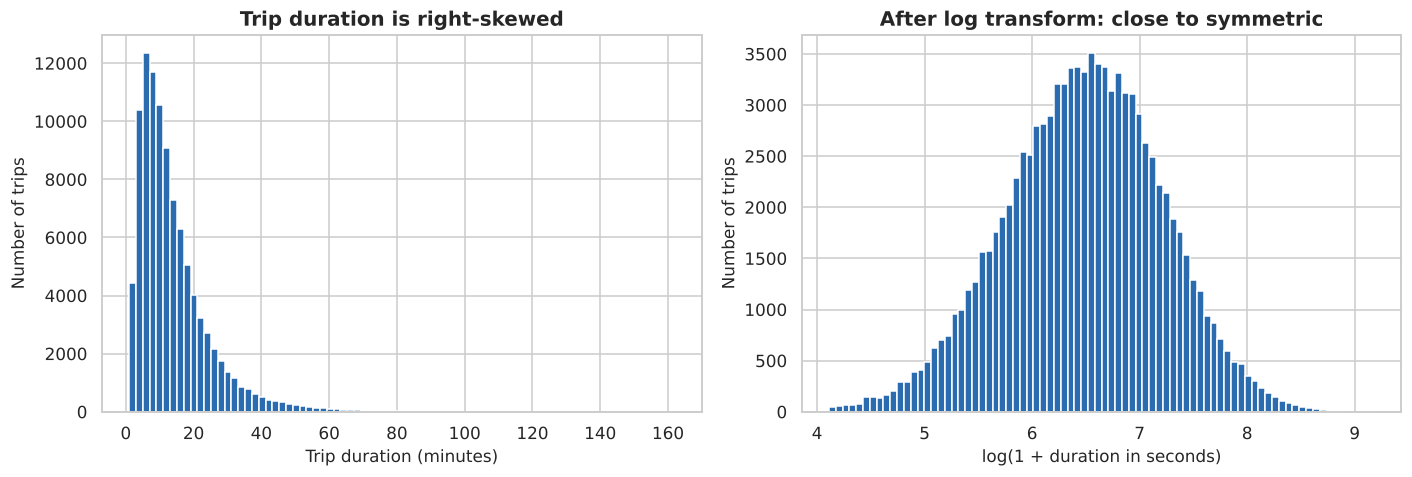

In [15]:
# Figure 1 - Distribution of trip duration (Q1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].hist(clean["trip_duration"] / 60, bins=80, color=ACCENT, edgecolor="white")
ax[0].set(title="Trip duration is right-skewed", xlabel="Trip duration (minutes)", ylabel="Number of trips")
ax[1].hist(clean["log_duration"], bins=80, color=ACCENT, edgecolor="white")
ax[1].set(title="After log transform: close to symmetric", xlabel="log(1 + duration in seconds)", ylabel="Number of trips")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig01_duration_distribution.png", dpi=130, bbox_inches="tight"); plt.show()

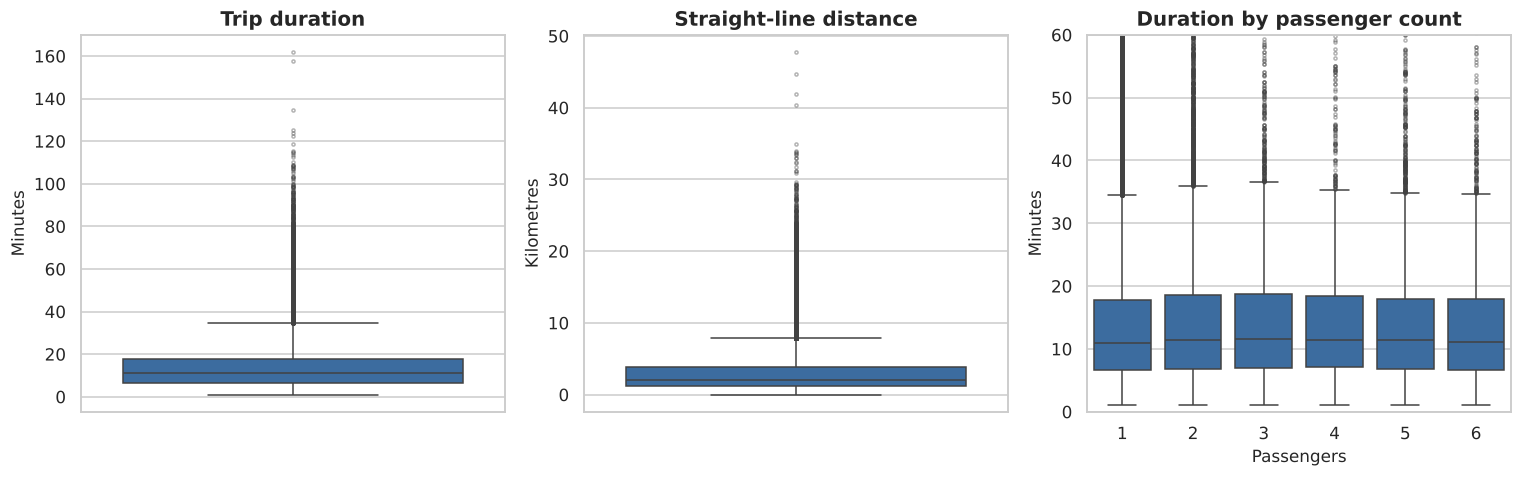

In [16]:
# Figure 2 - Spread and outliers (box plots) (Q1)
fig, ax = plt.subplots(1, 3, figsize=(14, 4.5))
sns.boxplot(y=clean["trip_duration"] / 60, ax=ax[0], color=ACCENT, flierprops={"markersize": 2, "alpha": 0.4})
ax[0].set(title="Trip duration", ylabel="Minutes")
sns.boxplot(y=clean["haversine_km"], ax=ax[1], color=ACCENT, flierprops={"markersize": 2, "alpha": 0.4})
ax[1].set(title="Straight-line distance", ylabel="Kilometres")
sns.boxplot(data=clean, x="passenger_count", y=clean["trip_duration"] / 60, ax=ax[2], color=ACCENT, flierprops={"markersize": 2, "alpha": 0.4})
ax[2].set(title="Duration by passenger count", xlabel="Passengers", ylabel="Minutes", ylim=(0, 60))
plt.tight_layout(); plt.savefig(FIG_DIR / "fig02_boxplots.png", dpi=130, bbox_inches="tight"); plt.show()

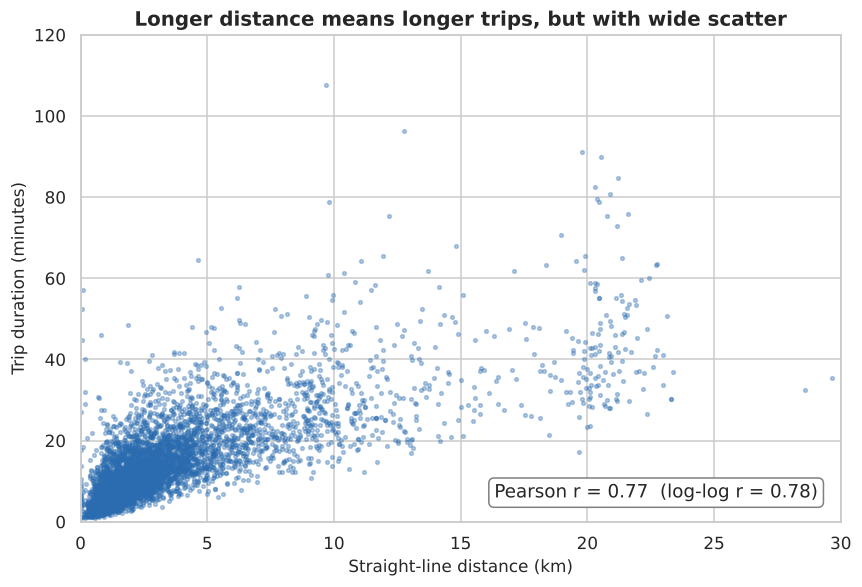

In [17]:
# Figure 3 - Distance vs duration (Q2)
samp = clean.sample(6000, random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(samp["haversine_km"], samp["trip_duration"] / 60, s=6, alpha=0.35, color=ACCENT)
ax.set(title="Longer distance means longer trips, but with wide scatter", xlabel="Straight-line distance (km)",
       ylabel="Trip duration (minutes)", xlim=(0, 30), ylim=(0, 120))
r = clean[["haversine_km", "trip_duration"]].corr().iloc[0, 1]
r_log = clean[["log_haversine", "log_duration"]].corr().iloc[0, 1]
ax.text(0.97, 0.05, f"Pearson r = {r:.2f}  (log-log r = {r_log:.2f})", transform=ax.transAxes, ha="right",
        bbox=dict(boxstyle="round", fc="white", ec="grey"))
plt.tight_layout(); plt.savefig(FIG_DIR / "fig03_distance_vs_duration.png", dpi=130, bbox_inches="tight"); plt.show()

pickup_hour       0        1        2        3        4        5        6        7        8        9        10       11       12       13       14       15       16       17       18       19       20       21       22       23
trips        3592.00  2569.00  1828.00  1395.00  1097.00  1041.00  2225.00  3768.00  4408.00  4622.00  4416.00  4701.00  5066.00  4808.00  5126.00  4922.00  4302.00  5261.00  6232.00  6242.00  5706.00  5812.00  5415.00  4685.00
mean_min       12.85    12.09    11.88    11.69    12.59    12.28    11.03    12.61    13.95    14.14    14.69    14.56    14.66    14.87    15.89    16.24    15.90    15.17    14.30    13.40    13.11    12.94    13.53    13.70
median_min     10.63     9.85    10.01     9.85    10.68     8.98     7.65     9.48    10.98    11.42    11.63    11.80    11.73    11.73    12.38    12.05    11.48    11.48    11.48    10.98    10.77    10.70    11.13    11.37


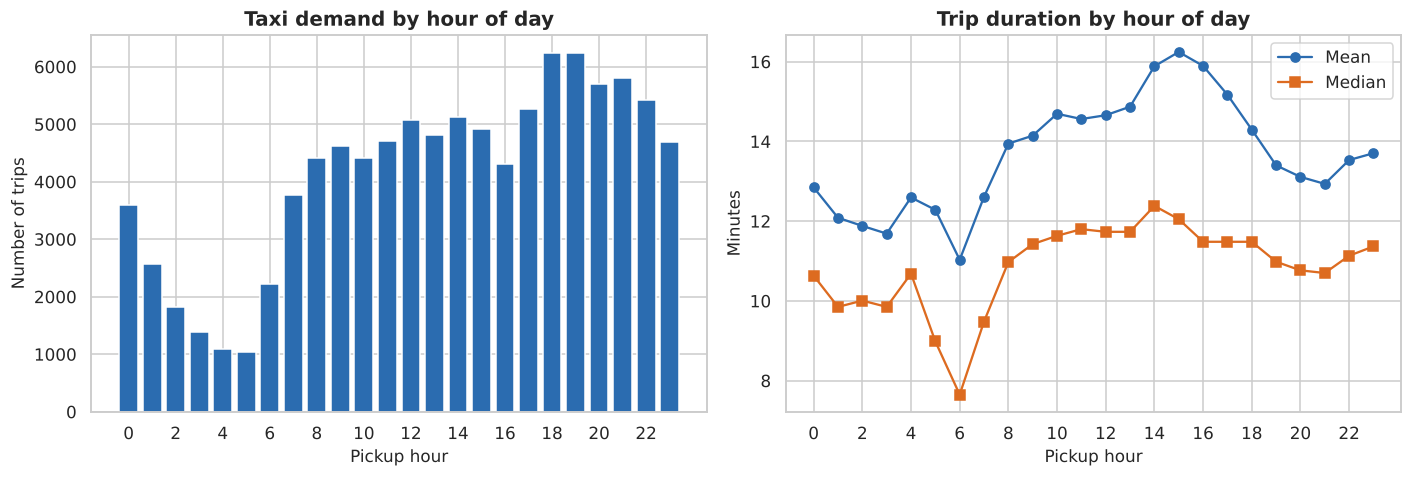

In [18]:
# Figure 4 - Demand and duration across the day (Q3)
hourly = clean.groupby("pickup_hour").agg(trips=("id", "size"), mean_min=("trip_duration", lambda s: s.mean() / 60),
                                          median_min=("trip_duration", lambda s: s.median() / 60))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].bar(hourly.index, hourly["trips"], color=ACCENT)
ax[0].set(title="Taxi demand by hour of day", xlabel="Pickup hour", ylabel="Number of trips", xticks=range(0, 24, 2))
ax[1].plot(hourly.index, hourly["mean_min"], marker="o", color=ACCENT, label="Mean")
ax[1].plot(hourly.index, hourly["median_min"], marker="s", color="#dd6b20", label="Median")
ax[1].set(title="Trip duration by hour of day", xlabel="Pickup hour", ylabel="Minutes", xticks=range(0, 24, 2))
ax[1].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "fig04_hourly_demand_duration.png", dpi=130, bbox_inches="tight"); plt.show()
display(hourly.round(2).T)

weekday_name       Mon       Tue       Wed       Thu       Fri       Sat       Sun
trips         12788.00  13738.00  14407.00  14918.00  15105.00  14965.00  13318.00
mean_min         13.49     14.38     14.67     15.05     14.65     12.98     12.64


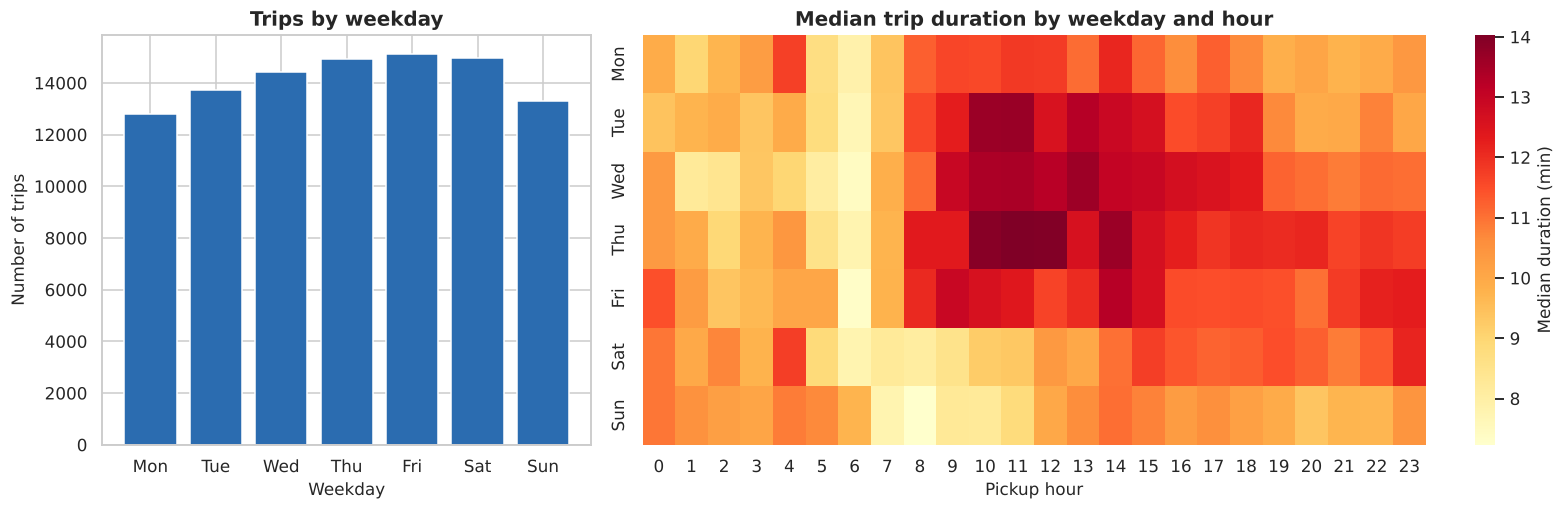

In [19]:
# Figure 5 - Weekday patterns and weekday x hour heatmap (Q3)
wd = clean.groupby("weekday_name", observed=True).agg(trips=("id", "size"), mean_min=("trip_duration", lambda s: s.mean() / 60))
heat = clean.pivot_table(index="weekday_name", columns="pickup_hour", values="trip_duration", aggfunc="median", observed=True) / 60
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 2]})
ax[0].bar(wd.index.astype(str), wd["trips"], color=ACCENT)
ax[0].set(title="Trips by weekday", xlabel="Weekday", ylabel="Number of trips")
sns.heatmap(heat, cmap="YlOrRd", ax=ax[1], cbar_kws={"label": "Median duration (min)"})
ax[1].set(title="Median trip duration by weekday and hour", xlabel="Pickup hour", ylabel="")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig05_weekday_patterns.png", dpi=130, bbox_inches="tight"); plt.show()
display(wd.round(2).T)

Lowest 3 days by trip count:
             trips  mean_min
pickup_date                 
2016-01-23     122     13.70
2016-01-24     253     11.58
2016-05-30     369     12.55

By month:
              trips  mean_min
pickup_month                 
1             15706     13.19
2             16140     13.15
3             17553     13.80
4             17170     14.20
5             16821     14.68
6             15849     14.97


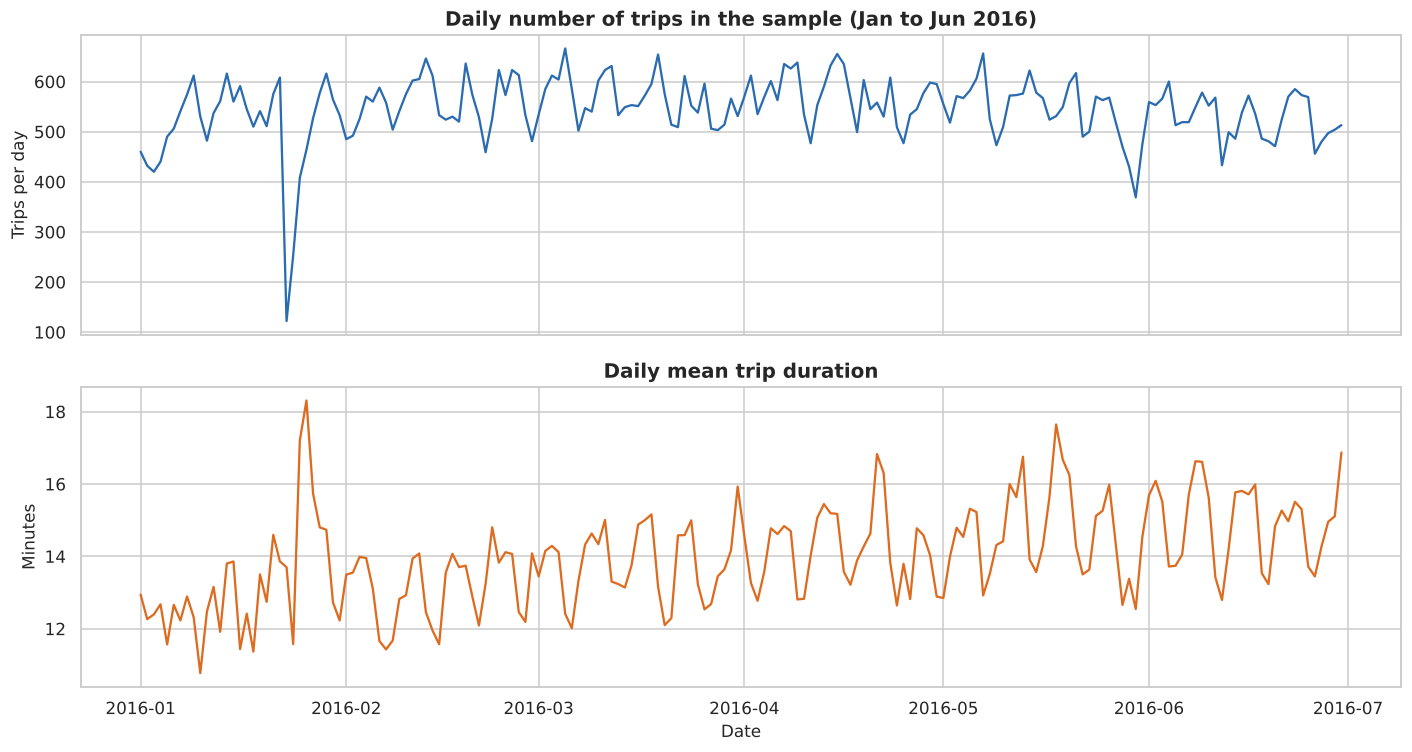

In [20]:
# Figure 6 - Trend over time (line chart) (Q3)
daily = clean.groupby("pickup_date").agg(trips=("id", "size"), mean_min=("trip_duration", lambda s: s.mean() / 60))
daily.index = pd.to_datetime(daily.index)
fig, ax = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
ax[0].plot(daily.index, daily["trips"], color=ACCENT)
ax[0].set(title="Daily number of trips in the sample (Jan to Jun 2016)", ylabel="Trips per day")
ax[1].plot(daily.index, daily["mean_min"], color="#dd6b20")
ax[1].set(title="Daily mean trip duration", ylabel="Minutes", xlabel="Date")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig06_daily_trend.png", dpi=130, bbox_inches="tight"); plt.show()
print("Lowest 3 days by trip count:")
print(daily.nsmallest(3, "trips").round(2).to_string())
monthly = clean.groupby("pickup_month").agg(trips=("id", "size"), mean_min=("trip_duration", lambda s: s.mean() / 60))
print("\nBy month:"); print(monthly.round(2).to_string())

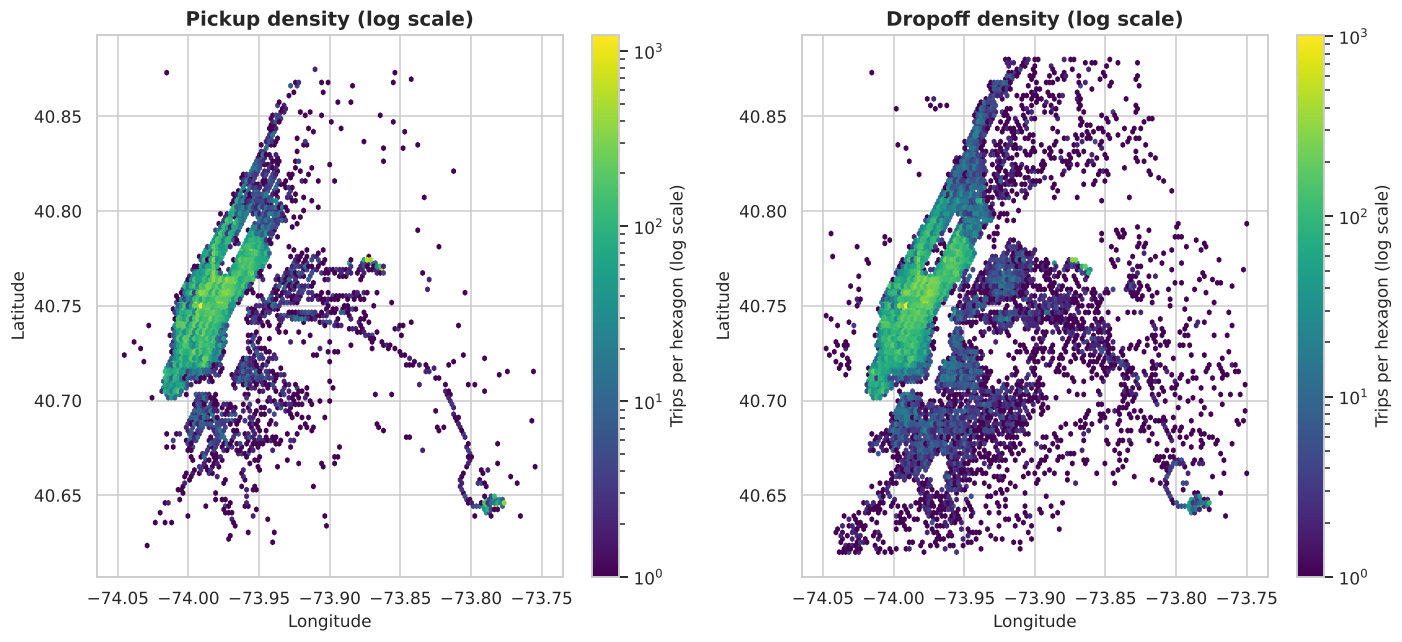

In [21]:
# Figure 7 - Where do trips start? (Q3/Q4)
fig, ax = plt.subplots(1, 2, figsize=(13, 6))
hb = ax[0].hexbin(clean["pickup_longitude"], clean["pickup_latitude"], gridsize=130, bins="log", cmap="viridis",
                  extent=(-74.05, -73.75, 40.62, 40.88), mincnt=1)
ax[0].set(title="Pickup density (log scale)", xlabel="Longitude", ylabel="Latitude"); plt.colorbar(hb, ax=ax[0], label="Trips per hexagon (log scale)")
hb2 = ax[1].hexbin(clean["dropoff_longitude"], clean["dropoff_latitude"], gridsize=130, bins="log", cmap="viridis",
                   extent=(-74.05, -73.75, 40.62, 40.88), mincnt=1)
ax[1].set(title="Dropoff density (log scale)", xlabel="Longitude", ylabel="Latitude"); plt.colorbar(hb2, ax=ax[1], label="Trips per hexagon (log scale)")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig07_pickup_dropoff_density.png", dpi=130, bbox_inches="tight"); plt.show()

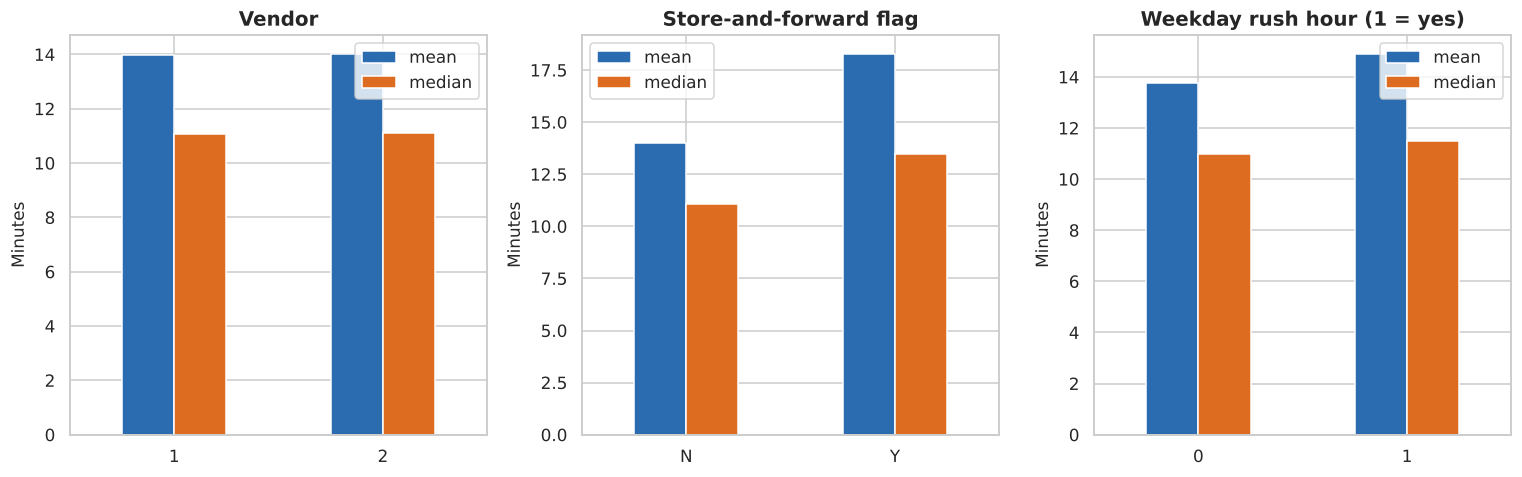

In [22]:
# Figure 8 - Categorical comparisons: vendor, store-and-forward flag, rush hour (Q4)
fig, ax = plt.subplots(1, 3, figsize=(14, 4.5))
for a, col, title in zip(ax, ["vendor_id", "store_and_fwd_flag", "is_rush_hour"],
                         ["Vendor", "Store-and-forward flag", "Weekday rush hour (1 = yes)"]):
    g = clean.groupby(col)["trip_duration"].agg(["mean", "median"]) / 60
    g.plot(kind="bar", ax=a, color=[ACCENT, "#dd6b20"], rot=0)
    a.set(title=title, xlabel="", ylabel="Minutes")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig08_category_comparison.png", dpi=130, bbox_inches="tight"); plt.show()

Correlation with trip_duration (strongest first):
haversine_km         0.766
manhattan_km         0.753
pickup_longitude     0.364
pickup_latitude     -0.237
dropoff_longitude    0.232
dropoff_latitude    -0.182
pickup_month         0.061
is_rush_hour         0.044
pickup_weekday      -0.036
pickup_hour          0.032
passenger_count      0.008
vendor_id            0.002


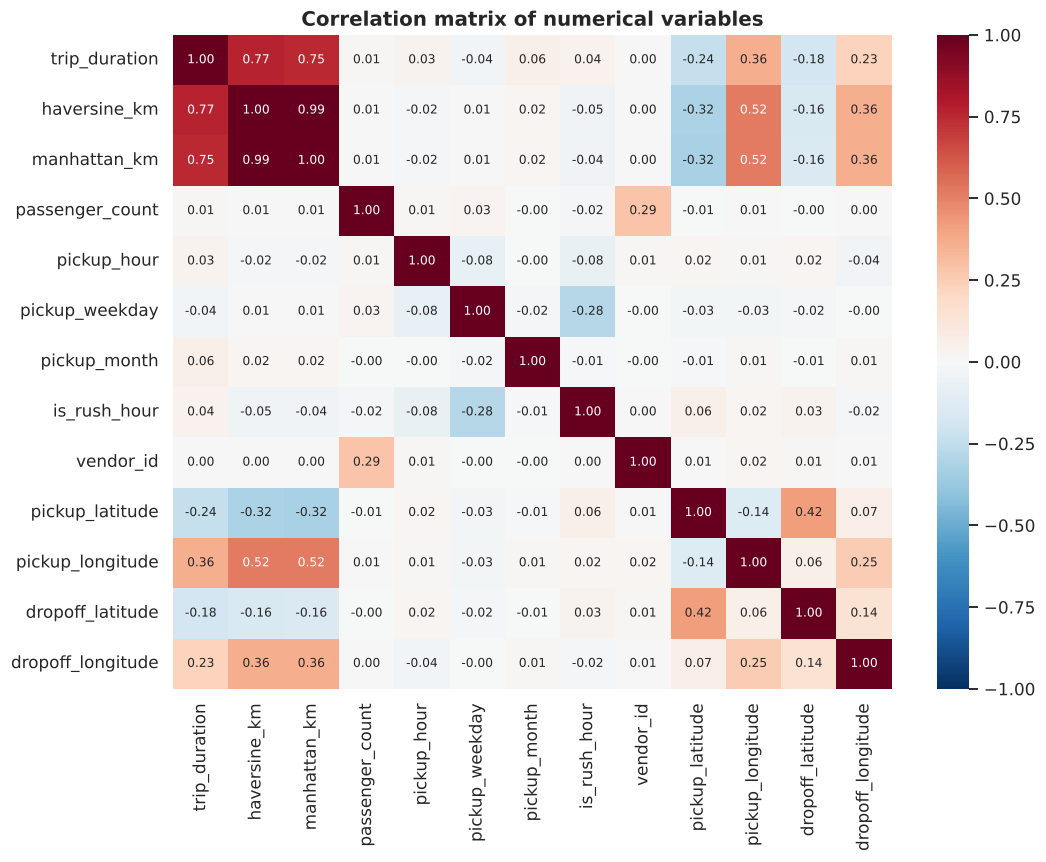

In [23]:
# Figure 9 - Correlation heatmap of numerical variables (Q2, Q4)
corr_cols = ["trip_duration", "haversine_km", "manhattan_km", "passenger_count", "pickup_hour", "pickup_weekday",
             "pickup_month", "is_rush_hour", "vendor_id", "pickup_latitude", "pickup_longitude", "dropoff_latitude", "dropoff_longitude"]
corr = clean[corr_cols].corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, annot_kws={"size": 8})
ax.set_title("Correlation matrix of numerical variables")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig09_correlation_heatmap.png", dpi=130, bbox_inches="tight"); plt.show()
print("Correlation with trip_duration (strongest first):")
print(corr["trip_duration"].drop("trip_duration").sort_values(key=abs, ascending=False).round(3).to_string())

### Interpretation of the visualizations
- **Fig 1–2 (distribution, box plots):** the middle half of trips take about 7 to 18 minutes. The right tail is long, which supports using a log transform before modelling.
- **Fig 3 (distance vs duration):** the relationship is clearly increasing (r = 0.77), but trips of the same distance differ by 2 to 3 times in duration. Distance alone leaves a lot unexplained, which is why time-of-day features matter.
- **Fig 4 (hourly):** demand is lowest at about 05:00 (1,041 trips) and highest in the evening (about 6,200 trips at 18:00–19:00). Mean duration is **longest in the afternoon (16.2 min at 15:00)** and shortest at 06:00 (11.0 min). Evening has the most trips but the afternoon has the slowest ones, which is consistent with congestion building up during the day.
- **Fig 5 (weekday × hour):** weekday daytime trips are the slowest (median up to 14 min on Tuesday to Thursday between 10:00 and 14:00), while Sunday morning is the fastest (about 7 min). Weekend trips average 12.8 min against 14.5 min on weekdays. Friday has the most trips and Monday the fewest.
- **Fig 6 (daily trend):** the quietest days are **23 January (122 trips)** and 24 January (253 trips), which coincide with the major snowstorm that hit New York on 22–24 January 2016, and **30 May (369 trips)**, which was Memorial Day. These dates come from outside the dataset and are noted only as a plausible explanation. Mean trip duration also **rises steadily from 13.2 min in January to 15.0 min in June (+13.5%)**.
- **Fig 7 (location density):** pickups concentrate in Manhattan (Midtown and Lower Manhattan), with two clear secondary clusters at the JFK and LaGuardia airports. Dropoffs are more widely spread across the outer boroughs.
- **Fig 8 (categories):** vendors and rush-hour status make little difference to the average duration (rush hour adds about 1 minute); the store-and-forward flag shows the larger gap discussed above.
- **Fig 9 (correlation):** only distance has a strong link with duration (haversine 0.77, Manhattan 0.75). Pickup longitude (0.36) is a weaker, indirect signal because the airports lie to the east. Hour, weekday, passenger count and vendor each have correlations below 0.07 with duration. **Correlation does not show causation:** for example, longitude does not make a trip longer; it marks where long airport trips start.

## Stage 5B: Predictive Modelling (Experiment 3.4)

**[Exp 3.4 – Task 1] Load the dataset and identify input features and target variable.**
The data is already loaded in a Pandas DataFrame (`clean`). The **target** is `trip_duration` (seconds), a continuous number, so this is a **regression** problem. The **inputs** are the 16 pickup-time features chosen in Stage 3.5.

In [24]:
X = clean[FEATURES]
y = clean[TARGET]
print("Input matrix  :", X.shape)
print("Target vector :", y.shape)
print("\nFeatures:", list(X.columns))
print("Task type: regression (continuous target in seconds)")

Input matrix  : (99239, 16)
Target vector : (99239,)

Features: ['vendor_id', 'passenger_count', 'store_fwd', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'pickup_hour', 'pickup_weekday', 'pickup_month', 'is_weekend', 'is_rush_hour', 'haversine_km', 'log_haversine', 'manhattan_km', 'bearing']
Task type: regression (continuous target in seconds)


**[Exp 3.4 – Task 2] Preprocess the dataset and divide it into training and testing sets.**
Preprocessing was done in Stage 3 (cleaning, derived features). Here the data is split **80% training / 20% testing** with a fixed random seed. The test set is never used to fit any model. The target is modelled on the log scale (`log1p`) because durations are heavily right-skewed, and predictions are converted back to seconds for all reported metrics.

In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)
y_train_log, y_test_log = np.log1p(y_train), np.log1p(y_test)
print(f"Training set: {X_train.shape[0]:,} trips")
print(f"Testing set : {X_test.shape[0]:,} trips")
print(f"\nMean duration  train: {y_train.mean():.1f} s   test: {y_test.mean():.1f} s  (similar, so the split is representative)")

Training set: 79,391 trips
Testing set : 19,848 trips

Mean duration  train: 840.6 s   test: 838.6 s  (similar, so the split is representative)


**[Exp 3.4 – Task 3] Train regression models using Scikit-learn.**
Four models are compared, from simple to flexible:
1. **Baseline:** always predicts the median training duration (a model must beat this to be useful).
2. **Linear Regression** on standardised features (interpretable, but assumes straight-line relationships).
3. **Random Forest Regressor** (many decision trees averaged).
4. **Histogram Gradient Boosting Regressor** (trees built one after another, each correcting the previous errors).

In [26]:
import time
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

models = {
    "Baseline (median)": DummyRegressor(strategy="median"),
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Random Forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=5, max_features=0.6,
                                           n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": HistGradientBoostingRegressor(learning_rate=0.08, max_iter=500, max_leaf_nodes=48,
                                                       early_stopping=True, validation_fraction=0.1,
                                                       n_iter_no_change=25, random_state=RANDOM_STATE),
}
fitted, fit_seconds = {}, {}
for name, model in models.items():
    t0 = time.time()
    model.fit(X_train, y_train_log)
    fitted[name], fit_seconds[name] = model, time.time() - t0
    print(f"{name:20s} trained in {fit_seconds[name]:5.1f} s")

Baseline (median)    trained in   0.0 s
Linear Regression    trained in   0.1 s
Random Forest        trained in  17.5 s
Gradient Boosting    trained in   3.2 s


**[Exp 3.4 – Task 4] Use the trained models to predict outcomes for the test records.**

In [27]:
predictions = {name: np.expm1(m.predict(X_test)).clip(min=1) for name, m in fitted.items()}   # back to seconds
print({k: v[:3].round(0).tolist() for k, v in predictions.items()})

{'Baseline (median)': [666.0, 666.0, 666.0], 'Linear Regression': [997.0, 271.0, 388.0], 'Random Forest': [819.0, 340.0, 355.0], 'Gradient Boosting': [825.0, 400.0, 321.0]}


**[Exp 3.4 – Task 7] Evaluate the predictions using appropriate metrics.**
- **MAE** (mean absolute error, seconds): the average size of the error, the main metric for regression in this lab.
- **RMSE** (seconds): penalises large errors more heavily.
- **Median AE** (seconds): the typical error, not distorted by a few extreme trips.
- **R² (log scale)** and **RMSLE**: how well relative errors are explained (RMSLE is the metric used in the original Kaggle competition).

In [28]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, median_absolute_error, r2_score

rows = []
for name, pred in predictions.items():
    rows.append({"Model": name,
                 "MAE (s)": mean_absolute_error(y_test, pred),
                 "RMSE (s)": mean_squared_error(y_test, pred) ** 0.5,
                 "Median AE (s)": median_absolute_error(y_test, pred),
                 "R2 (log scale)": r2_score(y_test_log, np.log1p(pred)),
                 "RMSLE": mean_squared_error(y_test_log, np.log1p(pred)) ** 0.5,
                 "Train time (s)": fit_seconds[name]})
results = pd.DataFrame(rows).set_index("Model").round(3)
display(results)
results.to_csv(OUT_DIR / "model_comparison.csv")

best_name = results.drop(index="Baseline (median)")["MAE (s)"].idxmin()
base_mae = results.loc["Baseline (median)", "MAE (s)"]
best_mae = results.loc[best_name, "MAE (s)"]
print(f"\nBest model by MAE: {best_name}  (MAE {best_mae:.1f} s = {best_mae/60:.2f} min)")
print(f"Improvement over baseline: {(1 - best_mae / base_mae):.1%}")

                   MAE (s)  RMSE (s)  Median AE (s)  R2 (log scale)  RMSLE  Train time (s)
Model                                                                                     
Baseline (median)  442.635   673.792        314.000          -0.001  0.729           0.020
Linear Regression  253.022   398.760        160.423           0.641  0.437           0.069
Random Forest      189.888   313.976        118.301           0.779  0.343          17.504
Gradient Boosting  177.837   295.597        111.623           0.798  0.328           3.204

Best model by MAE: Gradient Boosting  (MAE 177.8 s = 2.96 min)
Improvement over baseline: 59.8%


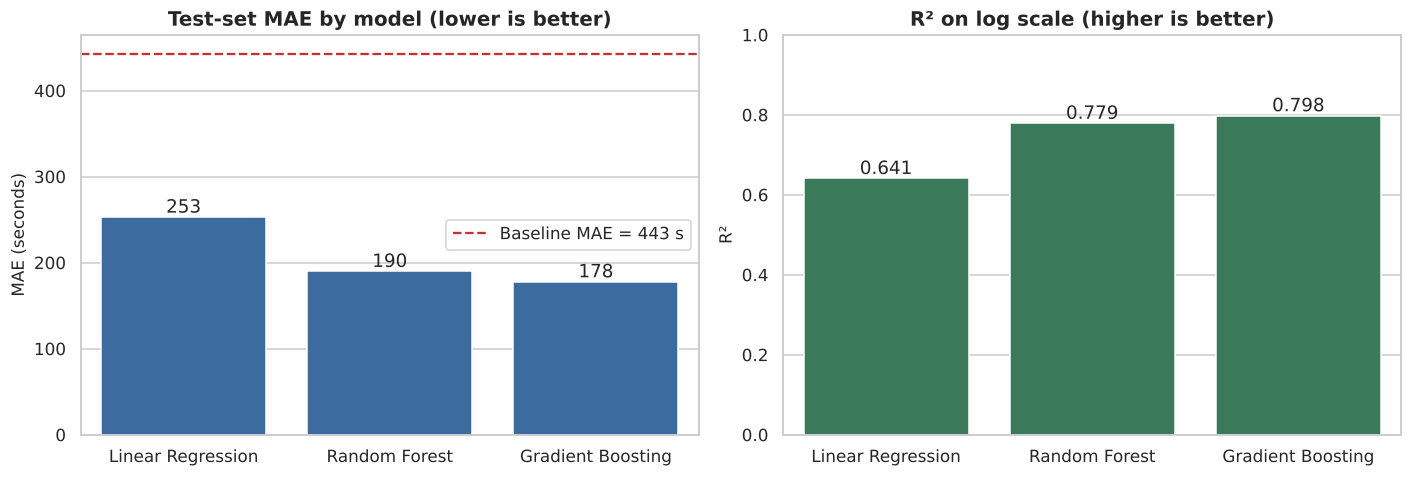

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
plot_df = results.drop(index="Baseline (median)").reset_index()
sns.barplot(data=plot_df, x="Model", y="MAE (s)", color=ACCENT, ax=ax[0])
ax[0].axhline(base_mae, color="#c53030", ls="--", label=f"Baseline MAE = {base_mae:.0f} s")
ax[0].set(title="Test-set MAE by model (lower is better)", xlabel="", ylabel="MAE (seconds)"); ax[0].legend()
for p in ax[0].patches:
    ax[0].annotate(f"{p.get_height():.0f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
sns.barplot(data=plot_df, x="Model", y="R2 (log scale)", color="#2f855a", ax=ax[1])
ax[1].set(title="R² on log scale (higher is better)", xlabel="", ylabel="R²", ylim=(0, 1))
for p in ax[1].patches:
    ax[1].annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig10_model_comparison.png", dpi=130, bbox_inches="tight"); plt.show()

**[Exp 3.4 – Tasks 5 and 6] Compare predicted with actual values and display them in a structured table.**
The table below uses 15 random test trips and the best model.

In [30]:
best_pred = predictions[best_name]
avp = pd.DataFrame({
    "trip_id": clean.loc[X_test.index, "id"].values,
    "pickup_time": clean.loc[X_test.index, "pickup_datetime"].dt.strftime("%a %H:%M").values,
    "distance_km": clean.loc[X_test.index, "haversine_km"].round(2).values,
    "actual_sec": y_test.values,
    "predicted_sec": best_pred.round(0),
})
avp["error_sec"] = (avp["predicted_sec"] - avp["actual_sec"]).round(0)
avp["abs_error_sec"] = avp["error_sec"].abs()
avp["abs_error_%"] = (avp["abs_error_sec"] / avp["actual_sec"] * 100).round(1)
avp["actual_min"] = (avp["actual_sec"] / 60).round(1)
avp["predicted_min"] = (avp["predicted_sec"] / 60).round(1)
avp.to_csv(OUT_DIR / "actual_vs_predicted_test.csv", index=False)      # full test set saved
print(f"Model: {best_name}   |   showing 15 of {len(avp):,} test trips (full table saved to outputs/)\n")
display(avp.sample(15, random_state=7).reset_index(drop=True))

Model: Gradient Boosting   |   showing 15 of 19,848 test trips (full table saved to outputs/)

      trip_id pickup_time  distance_km  actual_sec  predicted_sec  error_sec  abs_error_sec  abs_error_%  actual_min  predicted_min
0   id0810403   Wed 12:06         1.24         800          555.0     -245.0          245.0         30.6        13.3            9.2
1   id2817004   Tue 07:02         8.10        1663          911.0     -752.0          752.0         45.2        27.7           15.2
2   id2642698   Fri 18:20         1.59        1413          711.0     -702.0          702.0         49.7        23.6           11.8
3   id3231237   Mon 15:35         1.14         171          282.0      111.0          111.0         64.9         2.8            4.7
4   id3435213   Thu 20:10         0.83         189          167.0      -22.0           22.0         11.6         3.2            2.8
5   id0221640   Tue 14:24         2.90         562          533.0      -29.0           29.0          5.2         

Predictions within 2 min of actual: 52.9%   within 5 min: 84.3%   within 10 min: 95.9%


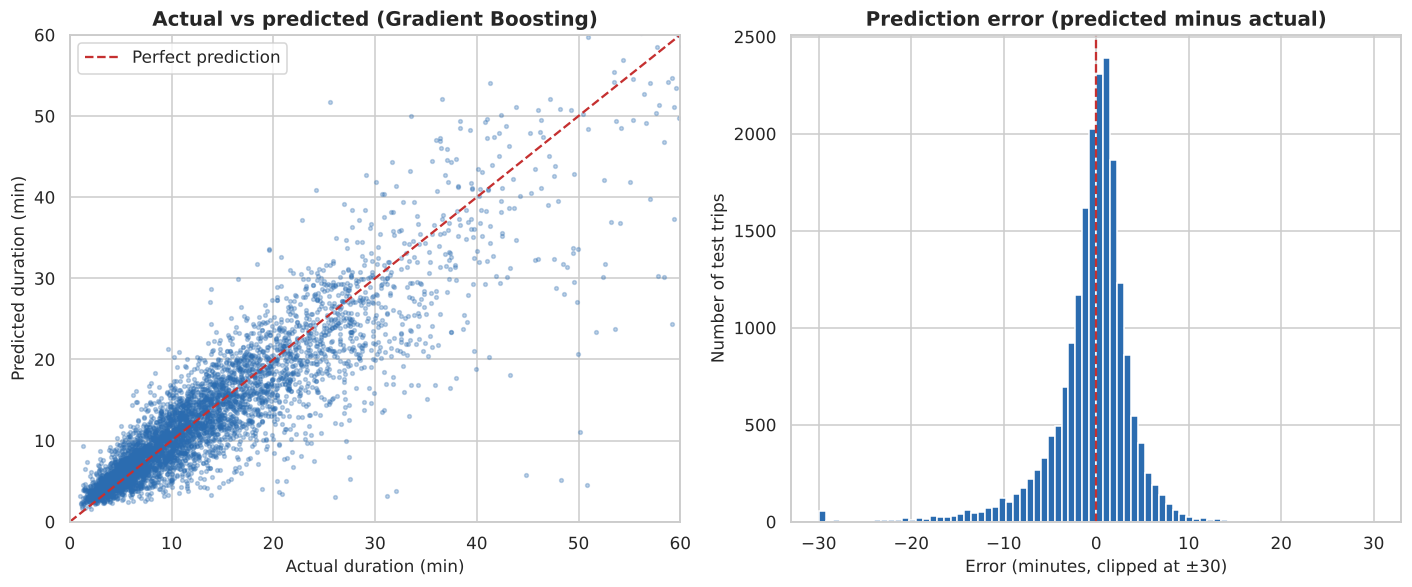

In [31]:
# Visual comparison of predicted and actual durations
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
s = avp.sample(5000, random_state=RANDOM_STATE)
ax[0].scatter(s["actual_sec"] / 60, s["predicted_sec"] / 60, s=6, alpha=0.3, color=ACCENT)
lim = 60
ax[0].plot([0, lim], [0, lim], color="#c53030", ls="--", label="Perfect prediction")
ax[0].set(title=f"Actual vs predicted ({best_name})", xlabel="Actual duration (min)", ylabel="Predicted duration (min)", xlim=(0, lim), ylim=(0, lim)); ax[0].legend()
resid = (avp["predicted_sec"] - avp["actual_sec"]) / 60
ax[1].hist(resid.clip(-30, 30), bins=80, color=ACCENT, edgecolor="white")
ax[1].axvline(0, color="#c53030", ls="--")
ax[1].set(title="Prediction error (predicted minus actual)", xlabel="Error (minutes, clipped at ±30)", ylabel="Number of test trips")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig11_actual_vs_predicted.png", dpi=130, bbox_inches="tight"); plt.show()
within = lambda m: (avp["abs_error_sec"] <= m * 60).mean()
print(f"Predictions within 2 min of actual: {within(2):.1%}   within 5 min: {within(5):.1%}   within 10 min: {within(10):.1%}")

### Where does the model do well and badly? (error analysis)

           trips  mean_actual_min  MAE_sec  MAPE_pct
dist_band                                           
<1 km       3242              5.7    129.9      38.8
1-2 km      6171              8.9    133.0      25.4
2-4 km      5622             14.0    168.8      20.2
4-8 km      2914             20.9    231.5      18.8
8-15 km     1232             29.8    313.7      17.5
>15 km       617             44.1    421.6      15.7


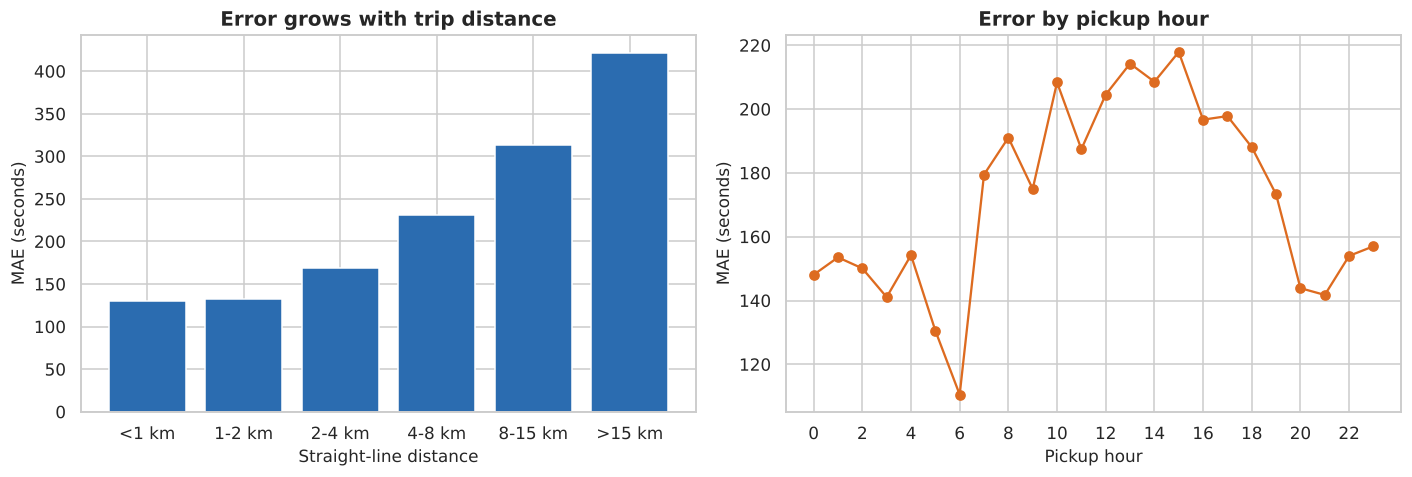

In [32]:
err = avp.copy()
err["hour"] = clean.loc[X_test.index, "pickup_hour"].values
err["dist_band"] = pd.cut(err["distance_km"], [0, 1, 2, 4, 8, 15, 100], labels=["<1 km", "1-2 km", "2-4 km", "4-8 km", "8-15 km", ">15 km"])
by_dist = err.groupby("dist_band", observed=True).agg(trips=("trip_id", "size"), mean_actual_min=("actual_min", "mean"),
                                                      MAE_sec=("abs_error_sec", "mean"), MAPE_pct=("abs_error_%", "mean"))
display(by_dist.round(1))
by_hour = err.groupby("hour").agg(MAE_sec=("abs_error_sec", "mean"), MAPE_pct=("abs_error_%", "mean"))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].bar(by_dist.index.astype(str), by_dist["MAE_sec"], color=ACCENT)
ax[0].set(title="Error grows with trip distance", xlabel="Straight-line distance", ylabel="MAE (seconds)")
ax[1].plot(by_hour.index, by_hour["MAE_sec"], marker="o", color="#dd6b20")
ax[1].set(title="Error by pickup hour", xlabel="Pickup hour", ylabel="MAE (seconds)", xticks=range(0, 24, 2))
plt.tight_layout(); plt.savefig(FIG_DIR / "fig12_error_analysis.png", dpi=130, bbox_inches="tight"); plt.show()

haversine_km         76.0
pickup_hour           8.0
bearing               5.0
pickup_weekday        2.7
dropoff_latitude      2.6
pickup_longitude      1.7
dropoff_longitude     1.6
pickup_latitude       1.4


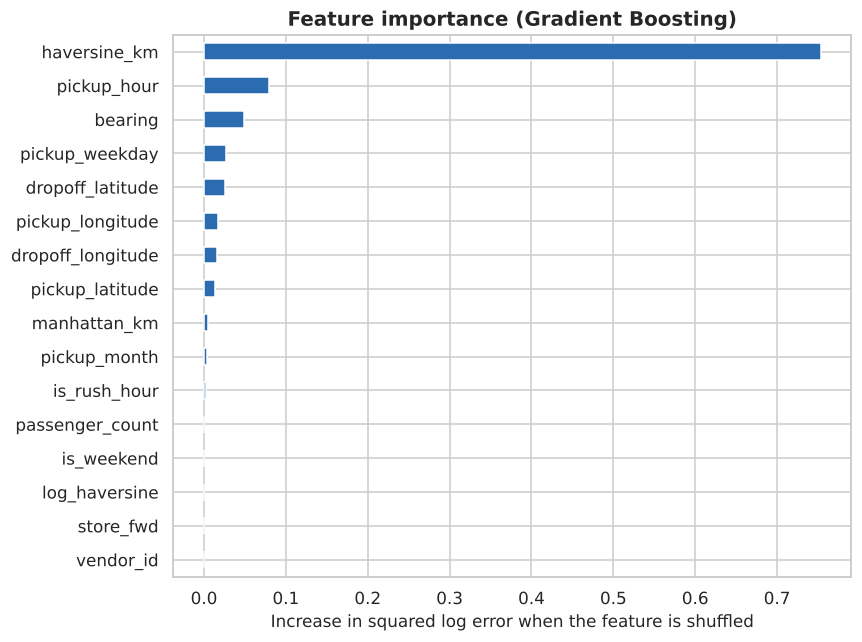

In [33]:
# Which features drive the predictions? (permutation importance on a test subset)
from sklearn.inspection import permutation_importance

sub = X_test.sample(5000, random_state=RANDOM_STATE)
pi = permutation_importance(fitted[best_name], sub, np.log1p(y_test.loc[sub.index]), n_repeats=5,
                            random_state=RANDOM_STATE, scoring="neg_mean_squared_error")
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
imp.plot(kind="barh", color=ACCENT, ax=ax)
ax.set(title=f"Feature importance ({best_name})", xlabel="Increase in squared log error when the feature is shuffled")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig13_feature_importance.png", dpi=130, bbox_inches="tight"); plt.show()
print((imp / imp.sum() * 100).sort_values(ascending=False).round(1).head(8).to_string())

**New input observations.** The trained model can also predict for trips that are *not* in the dataset. Three hypothetical trips are entered below using only information known at pickup time.

In [34]:
new_trips = pd.DataFrame({
    "route": ["Times Square to Wall Street, Wed 08:30", "Times Square to Wall Street, Sun 03:00", "Grand Central to JFK Airport, Fri 17:30"],
    "vendor_id": [2, 2, 2], "passenger_count": [1, 1, 2],
    "pickup_datetime": ["2016-05-11 08:30:00", "2016-05-15 03:00:00", "2016-05-13 17:30:00"],
    "pickup_longitude": [-73.9855, -73.9855, -73.9772], "pickup_latitude": [40.7580, 40.7580, 40.7527],
    "dropoff_longitude": [-74.0088, -74.0088, -73.7781], "dropoff_latitude": [40.7060, 40.7060, 40.6413],
    "store_and_fwd_flag": ["N", "N", "N"]})
new_feat = add_features(new_trips)
new_pred = np.expm1(fitted[best_name].predict(new_feat[FEATURES]))
display(pd.DataFrame({"route": new_trips["route"], "distance_km": new_feat["haversine_km"].round(1),
                      "predicted_min": (new_pred / 60).round(1)}))

                                     route  distance_km  predicted_min
0   Times Square to Wall Street, Wed 08:30          6.1           26.7
1   Times Square to Wall Street, Sun 03:00          6.1           17.9
2  Grand Central to JFK Airport, Fri 17:30         20.9           68.6


In [35]:
# Quick robustness check: 5-fold cross-validation of the best model on the training set
from sklearn.model_selection import cross_val_score
cv = cross_val_score(models[best_name].__class__(**models[best_name].get_params()), X_train, y_train_log,
                     cv=5, scoring="neg_root_mean_squared_error", n_jobs=1)
print(f"{best_name}: 5-fold CV RMSLE = {-cv.mean():.4f} (+/- {cv.std():.4f}),  held-out test RMSLE = {results.loc[best_name, 'RMSLE']:.4f}")
print("Similar CV and test scores indicate the model is not overfitted to a lucky split.")

Gradient Boosting: 5-fold CV RMSLE = 0.3263 (+/- 0.0032),  held-out test RMSLE = 0.3280
Similar CV and test scores indicate the model is not overfitted to a lucky split.


### Interpretation of the modelling results
- **All three models beat the baseline.** The median-only baseline has a test MAE of **443 s (7.4 min)**. Linear Regression reduces it to 253 s, Random Forest to 190 s and **Gradient Boosting to 178 s (2.96 min), a 59.8% improvement**.
- **Gradient Boosting is best on every metric:** MAE 177.8 s, RMSE 295.6 s, median absolute error 111.6 s (typical error under 2 minutes), R² on the log scale 0.798 and RMSLE 0.328. It also trains in about 3 seconds, much faster than the Random Forest (about 16 seconds).
- **Accuracy in practical terms:** 52.9% of test predictions are within 2 minutes of the actual duration, **84.3% within 5 minutes** and 95.9% within 10 minutes.
- **No sign of overfitting:** 5-fold cross-validation on the training data gives an RMSLE of 0.326 (± 0.003), almost identical to the held-out test score of 0.328.
- **What drives the predictions:** distance features dominate (haversine distance alone accounts for about 76% of the permutation importance, and the other distance features are highly correlated with it), followed by pickup hour (8%), travel direction/bearing (5%) and weekday (2.7%). Passenger count and vendor contribute almost nothing, matching the EDA.
- **Error pattern:** the absolute error grows with distance (130 s for trips under 1 km, 422 s above 15 km), but the relative error shrinks (39% for trips under 1 km, 16% above 15 km). Very short trips are hard to predict because their time is dominated by traffic lights, hailing and waiting rather than distance.
- **Sanity check on new trips:** the model predicts 26.7 min for Times Square to Wall Street at 08:30 on a Wednesday but 17.9 min at 03:00 on a Sunday, and 68.6 min for Grand Central to JFK on a Friday at 17:30. All are plausible and show that the model has learned time-of-day effects.

## Stage 6: Interpretation, Documentation and Presentation

**[Exp 3.4 – Task 8] Interpretation of results, usefulness and limitations of the predictions.**

### Summary of findings
- Trip duration in this sample has a median of 11.1 min and is mainly determined by **trip distance (r = 0.77)**, with a smaller but visible effect of **time of day, weekday and season** (afternoon and weekday trips are slower; average duration rose by about 13% from January to June).
- A **Gradient Boosting regression model** predicts duration with a test **MAE of about 3.0 minutes** (178 s), versus 7.4 minutes for a naive baseline, and 84% of predictions fall within 5 minutes of the actual value.

### Usefulness
- Good enough for **ETA display, rough fare estimates, dispatch and demand planning**, and for comparing typical times between areas and times of day.
- It is cheap to run (a trained model predicts in milliseconds) and needs only pickup and dropoff coordinates plus the pickup time.

### Limitations
- **Missing information:** the data has no weather, live traffic, road closures, accidents or events, which cause most of the large errors (for example one test trip of 8.1 km at 07:02 on a Tuesday took 27.7 min but was predicted at 15.2 min). Errors of more than 10 minutes still occur for about 4% of trips.
- **Straight-line distance** is used instead of the actual route; bridges, one-way streets and highways are not captured.
- **Under-prediction of very long trips:** the model is trained on log durations, which pushes predictions toward typical values, so extreme trips are underestimated (visible below the diagonal in the actual-vs-predicted plot).
- **Limited coverage:** only 6 months of 2016 and a 100,000-trip sample; it may not hold for other seasons, years, or after changes in ride-hailing and congestion pricing.
- **Predicting is not explaining:** the model finds associations only. For example, the rising duration from January to June could reflect weather, construction or traffic growth; the data cannot say which.

### Possible improvements
1. Add **weather** (rain, snow, temperature) and **public-holiday** features; the snowstorm and Memorial Day dips already show their effect.
2. Replace straight-line distance with **road-network route distance and time** (for example from OSRM), and add **pickup/dropoff zone clusters**.
3. Train on the **full 1.46 million trips**, tune hyperparameters with cross-validation, and try ensembles (for example boosting plus random forest).
4. Use **quantile regression** to give a time range (for example 12 to 18 minutes) instead of a single number, which is more honest about uncertainty.

### Conclusion
Trip distance and time of day make taxi trip duration reasonably predictable, and a gradient-boosting model cuts the average error by about 60% compared with a naive guess. The remaining error is mainly due to factors outside the dataset, mostly traffic and weather, so the predictions are best used as **estimates with a typical error of about 3 minutes**, not exact times.

In [36]:
# Save a one-page summary of key numbers for the report and slides
summary_out = {
    "records_raw": int(len(raw)), "records_clean": int(len(clean)), "records_removed": int(len(raw) - len(clean)),
    "median_duration_min": round(clean["trip_duration"].median() / 60, 2),
    "mean_duration_min": round(clean["trip_duration"].mean() / 60, 2),
    "corr_distance_duration": round(float(clean[["haversine_km", "trip_duration"]].corr().iloc[0, 1]), 3),
    "best_model": best_name, "best_MAE_sec": round(float(best_mae), 1), "baseline_MAE_sec": round(float(base_mae), 1),
    "best_R2_log": float(results.loc[best_name, "R2 (log scale)"]), "best_RMSLE": float(results.loc[best_name, "RMSLE"]),
}
import json
Path(OUT_DIR / "key_results.json").write_text(json.dumps(summary_out, indent=2))
print(json.dumps(summary_out, indent=2))

{
  "records_raw": 100000,
  "records_clean": 99239,
  "records_removed": 761,
  "median_duration_min": 11.08,
  "mean_duration_min": 14.0,
  "corr_distance_duration": 0.766,
  "best_model": "Gradient Boosting",
  "best_MAE_sec": 177.8,
  "baseline_MAE_sec": 442.6,
  "best_R2_log": 0.798,
  "best_RMSLE": 0.328
}


### References
1. Kaggle. *New York City Taxi Trip Duration* competition. https://www.kaggle.com/competitions/nyc-taxi-trip-duration
2. NYC Taxi & Limousine Commission. *TLC Trip Record Data* (yellow taxi, 2016). https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page
3. Pedregosa et al. (2011). Scikit-learn: Machine Learning in Python. *JMLR* 12, 2825–2830.
4. McKinney, W. (2010). Data Structures for Statistical Computing in Python (Pandas). *Proc. SciPy 2010*.
5. Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering* 9(3).
6. Waskom, M. (2021). seaborn: statistical data visualization. *JOSS* 6(60), 3021.